# Benchmark Methods for Plant Disease Classification
## Classical, transfer-learning and multi-modal baselines for comparison with the custom CNN

*COMP6001 - Computer Vision and Multimodal Machine Learning - Final Project*

## Section 1 - Objective of this Notebook

A single model's score means little on its own: 95 % accuracy may be excellent or poor depending on what simpler methods achieve on the same data. This notebook therefore trains **seven benchmark methods** on exactly the same split as the custom CNN and compares them. The benchmarks cover four ideas:

* **classical machine learning on hand-crafted features** (SVM and random forest on colour histograms and HOG);
* **classical classifiers on learned deep features** (the same two classifiers on features from a pretrained ResNet18), which separates the effect of the *features* from the effect of the *classifier*;
* **transfer learning** (ResNet18 pretrained on ImageNet and fine-tuned);
* **multi-modal methods** that combine the image with other data: image + crop metadata (feature-level fusion), and image-text alignment that classifies a leaf by comparing it with the *text description* of every disease, including diseases never seen in training (zero-shot).

The notebook explains why each method was selected (Section 3), what is distinctive about each (Section 4), implements and evaluates them (Sections 6 - 14), and compares them with each other and with the custom CNN (Section 15).

## Section 2 - Evaluation Protocol and Multi-Modal Integration

**Fair comparison.** Every benchmark uses the same `data/splits.csv` as the custom CNN: the same training, validation and test images. Hyper-parameters are chosen on the **validation** images only. The **test** images are used once per model for the final numbers. Metrics are the same everywhere: accuracy and macro-averaged precision, recall and F1, plus the time and size of each model. The statistical tests that decide whether differences between models are real are done in the results notebook, using the predictions saved here.

**Integrating different types of data.** The dataset has three types of information for every sample: the image, a text description of the symptoms and tabular metadata (crop, cause type, pathogen). There are three standard ways to combine modalities (Baltrusaitis et al., 2019):

$$
\text{early (feature-level) fusion: } \hat y = g\big([\phi_{\text{img}}(x);\ \phi_{\text{meta}}(m)]\big),\qquad
\text{late fusion: } \hat y = \sum_{k} w_k\, g_k\big(\phi_k(\cdot)\big),
$$

$$
\text{joint embedding: } \hat y=\arg\max_c\ \cos\big(f(x),\, e(t_c)\big),
$$

where $x$ is the image, $m$ the metadata, $t_c$ the text description of class $c$, $\phi$ feature extractors and $f,e$ image and text encoders mapping into one shared space. This notebook implements **early fusion** (Section 13) and a **joint embedding** (Section 14). Audio is not part of this dataset, so the modalities integrated here are image, text and tabular data.

**Avoiding label leakage.** Metadata such as the pathogen name or the cause type, or the symptom text *given to each image as an input*, would reveal the class and make the task trivial. Only the **crop species** is used as an input: a grower knows which crop is growing, as Mohanty et al. (2016) point out, so this is realistic information. The symptom text is used as a *class description* (a prototype each image is compared with), never as a per-image input.

## Section 3 - Why These Benchmarks? Reasons for the Selection

| # | Benchmark | Paradigm | Reason for selecting it |
|---|---|---|---|
| 1 | SVM on hand-crafted features | Classical ML | The standard pre-deep-learning approach to leaf-disease recognition (for example an SVM pipeline for tomato leaf viruses, Mokhtar et al., 2015). Shows how far hand-designed features go without deep learning. |
| 2 | Random forest on hand-crafted features | Classical ML | Same features, a completely different classifier (an ensemble of trees instead of a margin-based method). Tells whether any difference comes from the classifier family. |
| 3 | SVM on ResNet18 deep features | Classical classifier on learned features | Keeps the classifier from Benchmark 1 but replaces the features. The gap between Benchmarks 1 and 3 isolates the value of **learned features**. |
| 4 | Random forest on ResNet18 deep features | Classical classifier on learned features | Same logic for the tree-based classifier; the gap between Benchmarks 2 and 4. |
| 5 | ResNet18, fine-tuned | Transfer learning | The strongest standard image-only baseline. Mohanty et al. (2016) found transfer learning always better than training from scratch; this benchmark measures what pretraining adds over the custom CNN. |
| 6 | Image + crop metadata (feature fusion) | Multi-modal, early fusion | Tests whether adding a second, cheap data type helps. Compared with the identical classifier on the image alone, so any difference is due to the added modality. |
| 7 | Image-text alignment | Multi-modal, joint embedding | Uses the symptom descriptions to classify images, and can recognise a disease that was **never seen in training** from its description alone. Tests whether text carries useful knowledge. |

Together the benchmarks follow the structure of the project proposal (SVM and random forest on hand-crafted and deep features, ResNet18 transfer learning) and add the two multi-modal methods needed to integrate and analyse different data types. The comparison between pairs (1 vs 3, 2 vs 4, 6 vs the same classifier without metadata) is designed so that each pair changes **one thing at a time**.

## Section 4 - Novelty of the Benchmark Methods

Each benchmark was a genuine advance when it appeared. What is new about each, and how it differs from the others, is summarised here.

**Support vector machine (Cortes and Vapnik, 1995).** The SVM chooses the decision boundary that maximises the margin between classes, which gives good generalisation from few samples, and the *kernel trick* lets it separate classes that are not linearly separable without computing the high-dimensional features explicitly. Its novelty compared with earlier classifiers such as the perceptron is the margin principle and the kernel.

**Random forest (Breiman, 2001).** A random forest averages many decision trees, each trained on a random resample of the data and, at every split, on a random subset of features. The randomness decorrelates the trees, so the ensemble has much lower variance than one tree and resists overfitting. Unlike the SVM it needs no feature scaling and gives a feature-importance measure.

**Histogram of oriented gradients (Dalal and Triggs, 2005).** Used here as the hand-crafted shape feature. It describes local edge directions in small cells with block-wise contrast normalisation, which made it robust to lighting changes and was the leading descriptor before deep learning.

**Residual networks and transfer learning (He et al., 2016; Yosinski et al., 2014).** ResNet introduced skip connections, $y=F(x)+x$, which let very deep networks train without the gradient vanishing. Transfer learning reuses the features of a network trained on ImageNet: Yosinski et al. showed that early layers learn general features (edges, textures) that transfer to other tasks, so only a small amount of target data is needed. What is new relative to the custom CNN is the *pretrained starting point* and the depth.

**Feature-level multi-modal fusion (Baltrusaitis et al., 2019).** The survey organises multi-modal learning into representation, translation, alignment, fusion and co-learning. Early fusion, concatenating the representations of different modalities, is the simplest fusion method; its novelty lies in letting one model exploit complementary information from several data types.

**Visual-semantic embedding and zero-shot learning (Lampert et al., 2014; Frome et al., 2013; Radford et al., 2021).** Instead of learning one output unit per class, these methods map images and class *descriptions* into a shared space and classify by similarity. Because a new class only needs a description, the model can recognise classes with **no training images** (zero-shot learning). CLIP (Radford et al., 2021) did this at very large scale with image-text pairs from the web; the benchmark here is a small-scale version using our own symptom descriptions, which recent work on plant diseases suggests is a promising direction (Benabbas et al., 2025).

**What is new in this project's use of the benchmarks.** The benchmarks themselves are established methods. The contribution is applying all of them to one dataset with identical splits and metrics, pairing them so each comparison changes one factor, and adding two multi-modal benchmarks that use the text and metadata of the dataset.

## Section 5 - Theory of the Benchmark Methods

**Soft-margin SVM with an RBF kernel.** For training pairs $(x_i,y_i)$ the SVM solves

$$
\min_{w,b,\xi}\ \frac12\lVert w\rVert^{2}+C\sum_{i}\xi_i \quad\text{s.t.}\quad y_i\big(w\cdot\varphi(x_i)+b\big)\ge 1-\xi_i,\ \ \xi_i\ge 0,
$$

where the slack variables $\xi_i$ allow some errors and $C$ controls how strongly they are punished. The kernel $k(x,x')=\varphi(x)\cdot\varphi(x')$ is the radial basis function $k(x,x')=\exp(-\gamma\lVert x-x'\rVert^{2})$. Several classes are handled by training one SVM for every pair of classes and voting.

**Random forest.** Each of $B$ trees is grown on a bootstrap sample. At every node the best split among a random subset of features is chosen by minimising the Gini impurity $G=1-\sum_{c}p_c^{2}$ of the child nodes, and the forest predicts by majority vote, $\hat y=\operatorname{mode}\{T_b(x)\}_{b=1}^{B}$.

**Logistic regression (used for the fusion experiment).** A linear model with softmax output, $p_c(x)=\dfrac{e^{w_c\cdot x+b_c}}{\sum_j e^{w_j\cdot x+b_j}}$, trained by minimising the cross-entropy plus an L2 penalty. It is used for the fusion experiment because it is simple and fast, so any difference between image-only and image + metadata comes from the data, not from a complicated model.

**Transfer learning with ResNet18.** The network is initialised with ImageNet weights $\theta_0$, its last layer is replaced by a new layer with 17 outputs, and *all* weights are fine-tuned with a small learning rate by minimising the cross-entropy $\mathcal{L}=-\sum_c y_c\log p_c$.

**Image-text alignment.** An image feature $f\in\mathbb{R}^{512}$ is mapped by a learned matrix $W$ into the space of the text vectors $t_c$ (TF-IDF vectors of the class descriptions, see below). The score of class $c$ is a scaled cosine similarity,

$$
s_c(x)=\tau\cdot\frac{(Wf)\cdot t_c}{\lVert Wf\rVert\,\lVert t_c\rVert},\qquad p_c(x)=\frac{e^{s_c}}{\sum_j e^{s_j}},
$$

where the temperature $\tau>0$ is learned. Only $W$ and $\tau$ are trained; the class vectors $t_c$ come from text. Because a class enters only through its text vector, a class that was **left out of training** can still be scored. **TF-IDF** weights a word $t$ in a description $d$ by $\mathrm{tf}(t,d)\cdot\big(\ln\frac{1+N}{1+\mathrm{df}(t)}+1\big)$, giving high weight to words that distinguish descriptions.

**Metrics.** Accuracy and macro-averaged precision, recall and F1, as defined in the custom CNN notebook, are used for all models.

## Section 6 - Setup

The next cell imports the libraries (scikit-learn for the classical models, scikit-image for HOG, PyTorch/torchvision for ResNet18 and the alignment model). Uncomment the `%pip` line if a package is missing.

In [2]:
# %pip install scikit-learn scikit-image torch torchvision pandas numpy matplotlib pillow tqdm joblib

import warnings
warnings.filterwarnings("ignore")

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from joblib import Parallel, delayed

from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.models import resnet18, ResNet18_Weights

**Configuration.** `QUICK_TEST = True` runs everything on a tiny subset in a few minutes to check that the notebook works; set it to `False` for the real run. `PRETRAINED = True` downloads the ImageNet weights of ResNet18 (about 45 MB) the first time, so an internet connection is needed. The fine-tuning uses only 5 epochs. Features are cached in `data/features/` so a re-run does not repeat the slow steps.

In [3]:
QUICK_TEST = False
PRETRAINED = True            # ImageNet weights for ResNet18 (needs internet on the first run)
FT_EPOCHS = 5                # fine-tuning epochs for ResNet18
FT_PATIENCE = 2
BATCH_SIZE = 32
LEARNING_RATE = 1e-4         # fine-tuning learning rate
SEED = 42

LIMIT = 150 if QUICK_TEST else None
if QUICK_TEST:
    FT_EPOCHS = 2

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE, "| quick test:", QUICK_TEST)

Device: mps | quick test: False


Folders and plotting style, as in the earlier notebooks. Predictions of every benchmark go to `results/predictions/` (the same place as the custom CNN's predictions), figures and tables go to `results/benchmarks/`.

In [4]:
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT_DIR / "data"
FEAT_DIR = DATA_DIR / "features"
RESULTS = ROOT_DIR / "results" / "benchmarks"
PRED_DIR = ROOT_DIR / "results" / "predictions"
for d in (FEAT_DIR, RESULTS, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)
SUFFIX = "_quick" if QUICK_TEST else ""

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_show(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

**Load the split and the multi-modal table.** `data/splits.csv` (from the dataset notebook) has, for every image, its class, split, crop and the class description. The same images and order are used for every benchmark. The helper `record` stores each model's results (accuracy, macro metrics, time and size) and saves its test predictions for the statistical tests later.

In [5]:
assert (DATA_DIR / "splits.csv").exists(), "data/splits.csv not found - run the dataset notebook first."
df = pd.read_csv(DATA_DIR / "splits.csv")
df["path"] = df["path"].map(lambda p: str(ROOT_DIR / p))
class_names = df.drop_duplicates("label").sort_values("label")["class_name"].tolist()
K = len(class_names)

frames = {}
for s in ["train", "val", "test"]:
    f = df[df["split"] == s]
    frames[s] = (f.sample(min(len(f), LIMIT), random_state=SEED) if LIMIT else f).reset_index(drop=True)
y = {s: frames[s]["label"].values.astype(int) for s in frames}
print({s: len(f) for s, f in frames.items()}, "| classes:", K)

results, test_preds = [], {}

def record(name, modality, y_pred, train_s, feat_ms, clf_ms, size):
    P, R, F1, _ = precision_recall_fscore_support(y["test"], y_pred, average="macro", zero_division=0)
    row = dict(model=name, modality=modality, accuracy=accuracy_score(y["test"], y_pred), macro_precision=P,
               macro_recall=R, macro_f1=F1, train_time_s=train_s, feature_ms_per_image=feat_ms,
               classifier_ms_per_image=clf_ms, size=size)
    results.append(row)
    test_preds[name] = np.asarray(y_pred)
    slug = name.lower().replace(" + ", "_").replace(" ", "_").replace("-", "_")
    pd.DataFrame({"path": frames["test"]["path"].map(lambda p: str(Path(p).relative_to(ROOT_DIR))),
                  "y_true": y["test"], "y_pred": y_pred}).to_csv(PRED_DIR / f"{slug}_test_predictions.csv", index=False)
    print(f"{name}: accuracy {row['accuracy']:.4f} | macro-F1 {F1:.4f} | train {train_s:.0f}s | "
          f"features {feat_ms:.1f} ms/img | classifier {clf_ms:.2f} ms/img | {size}")

{'train': 18786, 'val': 2348, 'test': 2349} | classes: 17


## Section 7 - Hand-Crafted Features (for Benchmarks 1 and 2)

Each image is reduced to one feature vector that combines **colour** and **shape**:

* a **colour histogram** with 16 bins per channel (48 values), the fraction of pixels in each intensity range, and
* a **HOG descriptor** (edge directions in $16\times16$ pixel cells, blocks of $2\times2$ cells with L2-Hys normalisation; formulas in the custom CNN notebook). To keep the benchmark fast the image is first reduced to $128\times128$ pixels, which gives $7\times7$ blocks $\times\,36=1764$ values.

The two parts are joined into a vector of $48+1764=1812$ values. Extraction uses all CPU cores. Results are saved to `data/features/` so this slow step runs only once.

In [6]:
def hand_features(path):
    im = Image.open(path).convert("RGB").resize((128, 128))
    a = np.asarray(im, dtype=np.float32) / 255
    colour = np.concatenate([np.histogram(a[..., k], bins=16, range=(0, 1))[0] for k in range(3)]) / (128 * 128)
    gray = np.asarray(im.convert("L"), dtype=np.float32) / 255
    shape = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")
    return np.concatenate([colour, shape]).astype(np.float32)

def cached(name, n_rows, compute):
    f = FEAT_DIR / f"{name}{SUFFIX}.npy"
    if f.exists():
        arr = np.load(f)
        if len(arr) == n_rows:
            return arr
    arr = compute()
    np.save(f, arr)
    return arr

# time one image serially to report the cost of feature extraction per image
t0 = time.time()
for p in frames["train"]["path"][:20]:
    hand_features(p)
hand_ms = (time.time() - t0) / 20 * 1000

H = {}
for s in ["train", "val", "test"]:
    H[s] = cached(f"hand_{s}", len(frames[s]),
                  lambda s=s: np.array(Parallel(n_jobs=-1)(delayed(hand_features)(p) for p in tqdm(frames[s]["path"], desc=f"hand {s}"))))
print({s: v.shape for s, v in H.items()}, f"| {hand_ms:.1f} ms per image (one core)")

{'train': (18786, 1812), 'val': (2348, 1812), 'test': (2349, 1812)} | 9.6 ms per image (one core)


## Section 8 - Benchmark 1: SVM on Hand-Crafted Features

Features are standardised (zero mean, unit variance per feature, because the SVM is sensitive to scale), then reduced to 150 principal components with PCA so that the RBF-SVM trains in minutes instead of hours. The regularisation constant $C$ is chosen from $\{1,10\}$ using the **validation** set; the model with the better validation macro-F1 is then evaluated once on the test set.

In [7]:
def fit_svm(Xtr, ytr, Xva, yva, n_pca=150):
    best = None
    for C in [1, 10]:
        model = make_pipeline(StandardScaler(), PCA(n_components=min(n_pca, len(Xtr) - 1, Xtr.shape[1]), random_state=SEED),
                              SVC(kernel="rbf", C=C, gamma="scale"))
        t0 = time.time()
        model.fit(Xtr, ytr)
        dt = time.time() - t0
        f1 = f1_score(yva, model.predict(Xva), average="macro", zero_division=0)
        print(f"  C = {C:>3}: validation macro-F1 {f1:.4f}  (fit {dt:.0f}s)")
        if best is None or f1 > best[0]:
            best = (f1, C, model, dt)
    return best

print("SVM on hand-crafted features")
f1_val, C_best, svm_h, t_svm = fit_svm(H["train"], y["train"], H["val"], y["val"])
t0 = time.time(); pred = svm_h.predict(H["test"]); clf_ms = (time.time() - t0) / len(pred) * 1000
n_sv = int(svm_h[-1].n_support_.sum())
record("SVM hand-crafted", "image", pred, t_svm, hand_ms, clf_ms, f"C={C_best}, {n_sv} support vectors")

SVM on hand-crafted features
  C =   1: validation macro-F1 0.7460  (fit 24s)
  C =  10: validation macro-F1 0.7737  (fit 26s)
SVM hand-crafted: accuracy 0.8501 | macro-F1 0.7968 | train 26s | features 9.6 ms/img | classifier 2.25 ms/img | C=10, 14765 support vectors


## Section 9 - Benchmark 2: Random Forest on Hand-Crafted Features

The same 1812 features are given to a random forest of 300 trees. A forest needs no feature scaling. At each split a random subset of $\sqrt{1812}\approx 42$ features is considered (the default). Using identical features as Benchmark 1 means that any difference comes from the classifier family only.

In [8]:
t0 = time.time()
rf_h = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(H["train"], y["train"])
t_rf = time.time() - t0
print("validation macro-F1:", round(f1_score(y["val"], rf_h.predict(H["val"]), average="macro", zero_division=0), 4))
t0 = time.time(); pred = rf_h.predict(H["test"]); clf_ms = (time.time() - t0) / len(pred) * 1000
nodes = sum(t.tree_.node_count for t in rf_h.estimators_)
record("Random forest hand-crafted", "image", pred, t_rf, hand_ms, clf_ms, f"300 trees, {nodes:,} nodes")

validation macro-F1: 0.6107
Random forest hand-crafted: accuracy 0.7531 | macro-F1 0.6116 | train 36s | features 9.6 ms/img | classifier 0.03 ms/img | 300 trees, 2,346,096 nodes


## Section 10 - Deep Features from a Pretrained ResNet18 (for Benchmarks 3, 4 and 6 - 7)

ResNet18 pretrained on ImageNet is used as a **frozen feature extractor**: images (resized to $224\times224$ and normalised with the ImageNet mean and standard deviation) pass through the network, and the 512-value output of the global average pooling layer, just before the final classifier, is kept. This vector summarises the image with features learned on a million photographs, with no training on our data. These deep features feed Benchmarks 3, 4, 6 and 7.

In [9]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])
train_tf = T.Compose([T.Resize((224, 224)), T.RandomRotation(20), T.RandomHorizontalFlip(),
                      T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.ToTensor(), T.Normalize(MEAN, STD)])

class PlantDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths, self.labels, self.tf = frame["path"].tolist(), frame["label"].astype(int).tolist(), tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

def make_resnet(num_classes=None):
    weights = ResNet18_Weights.DEFAULT if PRETRAINED else None
    m = resnet18(weights=weights)
    m.fc = nn.Linear(512, num_classes) if num_classes else nn.Identity()
    return m

extractor = make_resnet().to(DEVICE).eval()

def extract(split):
    loader = DataLoader(PlantDataset(frames[split], eval_tf), batch_size=64, shuffle=False, num_workers=0)
    out = []
    with torch.no_grad():
        for x, _ in tqdm(loader, desc=f"deep {split}", leave=False):
            out.append(extractor(x.to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

t0 = time.time()
D = {s: cached(f"deep_{s}", len(frames[s]), lambda s=s: extract(s)) for s in ["train", "val", "test"]}
deep_ms = (time.time() - t0) / sum(len(v) for v in D.values()) * 1000
print({s: v.shape for s, v in D.items()}, f"| about {deep_ms:.1f} ms per image (batched, {DEVICE})")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/sabyasachi/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:03<00:00, 15.4MB/s]


{'train': (18786, 512), 'val': (2348, 512), 'test': (2349, 512)} | about 6.0 ms per image (batched, mps)


## Section 11 - Benchmarks 3 and 4: SVM and Random Forest on Deep Features

The same two classifiers as in Benchmarks 1 and 2 are trained on the 512 deep features instead of the 1812 hand-crafted ones. Comparing the pairs (1 vs 3 and 2 vs 4) shows how much of the difference between "classical" and "deep" methods comes from the **features** rather than from the classifier.

In [10]:
print("SVM on deep features")
f1_val, C_best, svm_d, t_svm_d = fit_svm(D["train"], y["train"], D["val"], y["val"], n_pca=150)
t0 = time.time(); pred = svm_d.predict(D["test"]); clf_ms = (time.time() - t0) / len(pred) * 1000
record("SVM deep-features", "image", pred, t_svm_d, deep_ms, clf_ms, f"C={C_best}, {int(svm_d[-1].n_support_.sum())} support vectors")

t0 = time.time()
rf_d = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(D["train"], y["train"])
t_rf_d = time.time() - t0
t0 = time.time(); pred = rf_d.predict(D["test"]); clf_ms = (time.time() - t0) / len(pred) * 1000
record("Random forest deep-features", "image", pred, t_rf_d, deep_ms, clf_ms,
       f"300 trees, {sum(t.tree_.node_count for t in rf_d.estimators_):,} nodes")

SVM on deep features
  C =   1: validation macro-F1 0.9594  (fit 8s)
  C =  10: validation macro-F1 0.9661  (fit 7s)
SVM deep-features: accuracy 0.9728 | macro-F1 0.9642 | train 7s | features 6.0 ms/img | classifier 1.35 ms/img | C=10, 9320 support vectors
Random forest deep-features: accuracy 0.8723 | macro-F1 0.8035 | train 17s | features 6.0 ms/img | classifier 0.04 ms/img | 300 trees, 1,940,974 nodes


## Section 12 - Benchmark 5: ResNet18 with Transfer Learning

The whole ResNet18 is fine-tuned on our images, starting from the ImageNet weights, with a new 17-way output layer. The training uses the same augmentation as the custom CNN (rotation, flip, random crop), the Adam optimiser with a small learning rate ($10^{-4}$), cross-entropy loss, and early stopping on validation macro-F1. Only 5 epochs are used: a pretrained network converges quickly, which is part of the advantage of transfer learning. The best weights (by validation macro-F1) are kept.

In [11]:
def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    preds, targets, total = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, t in tqdm(loader, leave=False, desc="train" if train else "eval"):
            x, t = x.to(DEVICE), t.to(DEVICE)
            out = model(x)
            loss = F.cross_entropy(out, t)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * x.size(0)
            preds += out.argmax(1).cpu().tolist(); targets += t.cpu().tolist()
    return total / len(targets), f1_score(targets, preds, average="macro", zero_division=0), np.array(preds)

resnet = make_resnet(K).to(DEVICE)
loaders = {s: DataLoader(PlantDataset(frames[s], train_tf if s == "train" else eval_tf), batch_size=BATCH_SIZE,
                         shuffle=(s == "train"), num_workers=0) for s in frames}
opt = torch.optim.Adam(resnet.parameters(), lr=LEARNING_RATE)

best_f1, best_state, bad, t0 = -1, None, 0, time.time()
for ep in range(1, FT_EPOCHS + 1):
    tr_loss, tr_f1, _ = run_epoch(resnet, loaders["train"], opt)
    va_loss, va_f1, _ = run_epoch(resnet, loaders["val"])
    print(f"Epoch {ep}/{FT_EPOCHS} | train loss {tr_loss:.4f} macro-F1 {tr_f1:.4f} | val loss {va_loss:.4f} macro-F1 {va_f1:.4f}")
    if va_f1 > best_f1:
        best_f1, bad = va_f1, 0
        best_state = {k: v.detach().cpu().clone() for k, v in resnet.state_dict().items()}
    else:
        bad += 1
        if bad >= FT_PATIENCE:
            print("Early stopping"); break
t_ft = time.time() - t0

resnet.load_state_dict(best_state)
t0 = time.time()
_, _, pred = run_epoch(resnet, loaders["test"])
ft_ms = (time.time() - t0) / len(pred) * 1000
(Path(ROOT_DIR) / "models").mkdir(exist_ok=True)
torch.save({"model": best_state, "class_names": class_names}, ROOT_DIR / "models" / "resnet18_finetuned.pt")
record("ResNet18 fine-tuned", "image", pred, t_ft, 0.0, ft_ms, f"{sum(p.numel() for p in resnet.parameters()):,} parameters")

Epoch 1/5 | train loss 0.2710 macro-F1 0.9052 | val loss 0.0746 macro-F1 0.9763


Epoch 2/5 | train loss 0.0690 macro-F1 0.9785 | val loss 0.0819 macro-F1 0.9734


Epoch 3/5 | train loss 0.0450 macro-F1 0.9847 | val loss 0.0508 macro-F1 0.9854


Epoch 4/5 | train loss 0.0400 macro-F1 0.9865 | val loss 0.0398 macro-F1 0.9891


Epoch 5/5 | train loss 0.0307 macro-F1 0.9904 | val loss 0.0429 macro-F1 0.9881


ResNet18 fine-tuned: accuracy 0.9877 | macro-F1 0.9885 | train 1680s | features 0.0 ms/img | classifier 6.35 ms/img | 11,185,233 parameters


## Section 13 - Benchmark 6: Multi-Modal Feature Fusion (Image + Crop Metadata)

This is **early fusion**: the 512 deep image features are concatenated with the **crop species** from the metadata, written as a one-hot vector (for example Tomato $=(0,0,1)$), and a single classifier is trained on the joined vector,

$$
z=[\,\phi_{\text{img}}(x)\ ;\ \text{onehot}(\text{crop})\,],\qquad \hat y=g(z).
$$

To measure exactly what the second modality adds, the *same* logistic-regression classifier is also trained on the image features alone. Any difference between the two is caused by the metadata. Only the crop is used as input, never the pathogen, cause type or the symptom text, which would reveal the disease label (Section 2).

In [12]:
crops = sorted(df["crop"].unique())
def crop_onehot(split):
    return np.array([[c == k for k in crops] for c in frames[split]["crop"]], dtype=np.float32)
M = {s: crop_onehot(s) for s in frames}

def fit_lr(Xtr, Xva, label):
    scaler = StandardScaler().fit(Xtr)
    t0 = time.time()
    clf = LogisticRegression(max_iter=300, C=1.0).fit(scaler.transform(Xtr), y["train"])
    dt = time.time() - t0
    print(f"{label}: validation macro-F1 {f1_score(y['val'], clf.predict(scaler.transform(Xva)), average='macro', zero_division=0):.4f}")
    return scaler, clf, dt

sc_i, lr_i, t_i = fit_lr(D["train"], D["val"], "image only")
sc_f, lr_f, t_f = fit_lr(np.hstack([D["train"], M["train"]]), np.hstack([D["val"], M["val"]]), "image + crop")

t0 = time.time(); pred_img = lr_i.predict(sc_i.transform(D["test"])); ms_i = (time.time() - t0) / len(pred_img) * 1000
Xtest_f = np.hstack([D["test"], M["test"]])
t0 = time.time(); pred_fus = lr_f.predict(sc_f.transform(Xtest_f)); ms_f = (time.time() - t0) / len(pred_fus) * 1000
record("Logistic regression image-only", "image", pred_img, t_i, deep_ms, ms_i, f"{lr_i.coef_.size + lr_i.intercept_.size:,} parameters")
record("Fusion image + crop", "image + metadata", pred_fus, t_f, deep_ms, ms_f, f"{lr_f.coef_.size + lr_f.intercept_.size:,} parameters")

image only: validation macro-F1 0.9350
image + crop: validation macro-F1 0.9438
Logistic regression image-only: accuracy 0.9468 | macro-F1 0.9419 | train 3s | features 6.0 ms/img | classifier 0.02 ms/img | 8,721 parameters
Fusion image + crop: accuracy 0.9510 | macro-F1 0.9465 | train 2s | features 6.0 ms/img | classifier 0.00 ms/img | 8,772 parameters


**Analysis of the second modality.** Two questions: does the crop information change the scores, and what kind of mistakes does it remove? A *cross-crop error* is an image of one crop predicted as a disease of a different crop (for example a tomato leaf labelled as a potato disease), which the crop metadata should reduce (it is an input to the classifier, not a hard rule, so some may remain).

,input,accuracy,macro-F1,errors,cross-crop errors
0,image only,0.9468,0.9419,125,13
1,image + crop metadata,0.9510,0.9465,115,1


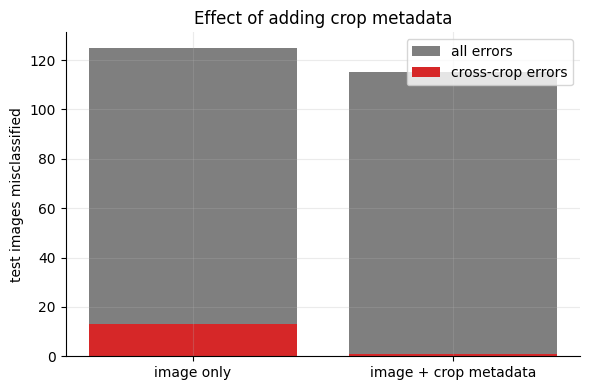

In [13]:
class_crop = df.drop_duplicates("label").sort_values("label")["crop"].tolist()
def cross_crop_errors(pred):
    return int(sum(class_crop[t] != class_crop[p] for t, p in zip(y["test"], pred)))

rows = []
for name, pred in [("image only", pred_img), ("image + crop metadata", pred_fus)]:
    P, R, F1, _ = precision_recall_fscore_support(y["test"], pred, average="macro", zero_division=0)
    rows.append((name, accuracy_score(y["test"], pred), F1, int((pred != y["test"]).sum()), cross_crop_errors(pred)))
fusion_table = pd.DataFrame(rows, columns=["input", "accuracy", "macro-F1", "errors", "cross-crop errors"])
display(fusion_table.round(4))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(fusion_table["input"], fusion_table["errors"], color="tab:gray", label="all errors")
ax.bar(fusion_table["input"], fusion_table["cross-crop errors"], color="tab:red", label="cross-crop errors")
ax.set_ylabel("test images misclassified"); ax.set_title("Effect of adding crop metadata")
ax.legend()
save_show("fusion_errors")

*How to read it.* If cross-crop errors were already rare, the pretrained image features recognise the crop easily and the metadata can add little, which is itself a valid result: a second modality only helps if it contains information the first one lacks.

## Section 14 - Benchmark 7: Image-Text Alignment and Zero-Shot Classification

In the dataset notebook every class received a text description of its symptoms. Here the text becomes part of the classifier. Each class description (prefixed with the crop name, for example "Tomato leaf. Large greasy water-soaked patches...") is turned into a TF-IDF vector $t_c$. A matrix $W$ is learned that maps the 512 image features into the same space, and an image is assigned to the class whose description it is most similar to (formula in Section 5).

This is a **joint embedding**, the principle behind CLIP, at a small scale. Two experiments are run:

1. **Supervised alignment:** trained on all 17 classes, evaluated on the test set like the other benchmarks.
2. **Zero-shot:** for each class in turn, that class is **removed from the training data** (its images and its description are not used), the model is trained on the other 16 classes, and test images of the removed class are classified among all 17 descriptions. The model never saw an image of the disease; it can only use the *text*. Chance level is $1/17\approx 5.9\,\%$ for top-1 and $3/17\approx 17.6\,\%$ for top-3.

The descriptions here are short and the TF-IDF encoder knows no word meanings (it only counts words), so the zero-shot results are expected to be modest; a pretrained text encoder would do better.

In [14]:
desc = df.drop_duplicates("label").sort_values("label").apply(lambda r: f"{r['crop']} leaf. {r['symptom_text']}", axis=1).tolist()
tfidf = TfidfVectorizer(stop_words="english")
Tm = torch.tensor(tfidf.fit_transform(desc).toarray(), dtype=torch.float32)       # (K, vocabulary), rows L2-normalised
Tm = F.normalize(Tm, dim=1)
print("text matrix:", tuple(Tm.shape), "(classes x vocabulary words)")

scaler_d = StandardScaler().fit(D["train"])
Xs = {s: torch.tensor(scaler_d.transform(D[s]), dtype=torch.float32) for s in D}

class Aligner(nn.Module):
    def __init__(self, d_img, d_text):
        super().__init__()
        self.W = nn.Linear(d_img, d_text, bias=False)
        self.log_tau = nn.Parameter(torch.tensor(2.5))
    def forward(self, x, text):
        z = F.normalize(self.W(x), dim=1)
        return self.log_tau.exp() * z @ text.T                      # scaled cosine similarity to every class text

def train_aligner(train_classes, epochs=30):
    keep = np.isin(y["train"], train_classes)
    X, yy = Xs["train"][keep], torch.tensor(y["train"][keep])
    idx = {c: i for i, c in enumerate(train_classes)}
    target = torch.tensor([idx[int(c)] for c in yy])
    model = Aligner(X.shape[1], Tm.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    text_tr = Tm[train_classes]
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 256):
            b = perm[i:i + 256]
            loss = F.cross_entropy(model(X[b], text_tr), target[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

t0 = time.time()
aligner = train_aligner(list(range(K)))
t_al = time.time() - t0
with torch.no_grad():
    t1 = time.time(); logits = aligner(Xs["test"], Tm); pred = logits.argmax(1).numpy(); clf_ms = (time.time() - t1) / len(pred) * 1000
n_al = sum(p.numel() for p in aligner.parameters())
record("Image-text alignment", "image + text", pred, t_al, deep_ms, clf_ms, f"{n_al:,} parameters")

text matrix: (17, 115) (classes x vocabulary words)
Image-text alignment: accuracy 0.9434 | macro-F1 0.9337 | train 2s | features 6.0 ms/img | classifier 0.00 ms/img | 58,881 parameters


**Zero-shot experiment.** For each class $k$ the aligner is retrained without class $k$ and then applied to the test images of class $k$. The bar chart shows the share of those images for which the correct class was ranked first (top-1) or among the first three (top-3), against chance. Classes whose description is very similar to another class (for example the healthy leaves of different crops) are naturally hard to separate by text.

,held-out class,test images,zero-shot top-1,zero-shot top-3
0,Apple - Apple scab,63,0.000,0.016
1,Apple - Black rot,62,0.000,0.000
2,Apple - Cedar apple rust,27,0.000,0.037
3,Apple - healthy,165,0.000,0.133
4,Potato - Early blight,100,0.020,0.360
5,Potato - Late blight,100,0.000,0.480
6,Potato - healthy,15,0.133,0.400
7,Tomato - Bacterial spot,213,0.000,0.019
8,Tomato - Early blight,100,0.000,0.040
9,Tomato - Late blight,191,0.000,0.042


Mean zero-shot top-1: 0.010 (chance 0.059) | top-3: 0.101 (chance 0.176)


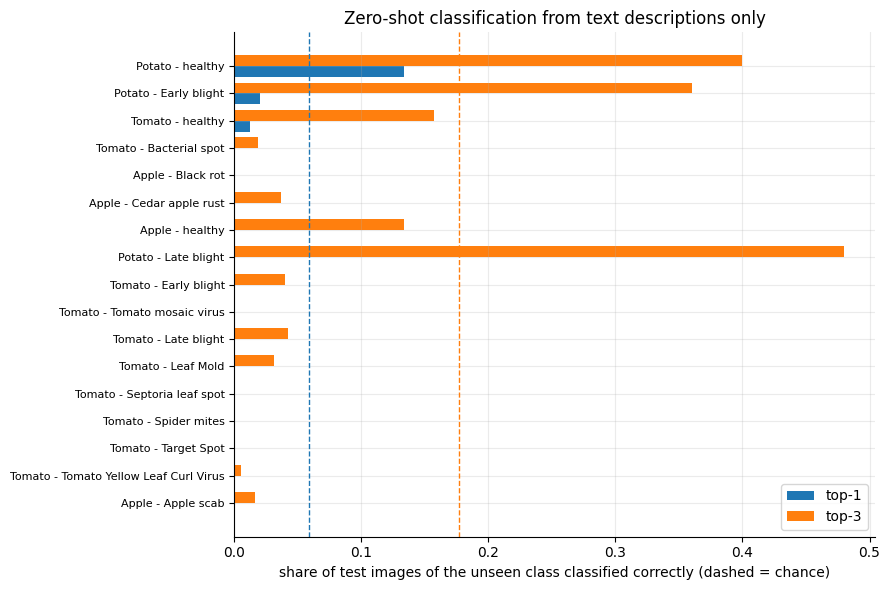

In [15]:
zs_rows = []
for k in range(K):
    mask = y["test"] == k
    if mask.sum() == 0:
        continue
    model = train_aligner([c for c in range(K) if c != k])
    with torch.no_grad():
        logit = model(Xs["test"][mask], Tm)
    rank = logit.argsort(dim=1, descending=True)
    zs_rows.append((class_names[k], int(mask.sum()),
                    (rank[:, 0] == k).float().mean().item(), (rank[:, :3] == k).any(dim=1).float().mean().item()))
zs = pd.DataFrame(zs_rows, columns=["held-out class", "test images", "zero-shot top-1", "zero-shot top-3"])
display(zs.round(3))
print(f"Mean zero-shot top-1: {zs['zero-shot top-1'].mean():.3f} (chance {1 / K:.3f}) | "
      f"top-3: {zs['zero-shot top-3'].mean():.3f} (chance {3 / K:.3f})")
zs.to_csv(RESULTS / "zero_shot_results.csv", index=False)

order = zs.sort_values("zero-shot top-1")
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(order))
ax.barh(yy - 0.2, order["zero-shot top-1"], 0.4, label="top-1", color="tab:blue")
ax.barh(yy + 0.2, order["zero-shot top-3"], 0.4, label="top-3", color="tab:orange")
ax.axvline(1 / K, color="tab:blue", ls="--", lw=1); ax.axvline(3 / K, color="tab:orange", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(order["held-out class"], fontsize=8)
ax.set_xlabel("share of test images of the unseen class classified correctly (dashed = chance)")
ax.set_title("Zero-shot classification from text descriptions only")
ax.legend(loc="lower right")
save_show("zero_shot")

## Section 15 - Comparison of All Benchmarks (and the Custom CNN)

All results are collected in one table. If the custom CNN notebook has been run, its results are loaded from `results/predictions/custom_cnn_metrics.json` and shown for comparison. The table is sorted by macro-F1, the metric that treats all classes equally. Time columns separate the cost of extracting features, which every classical model has to pay for every new image, from the cost of the classifier itself.

In [16]:
res = pd.DataFrame(results)
cnn_file = PRED_DIR / "custom_cnn_metrics.json"
cnn_pred_file = PRED_DIR / "custom_cnn_test_predictions.csv"
if cnn_file.exists():
    m = json.load(open(cnn_file))
    res = pd.concat([res, pd.DataFrame([dict(model="Custom CNN (ours)", modality="image", accuracy=m["accuracy"],
        macro_precision=m["macro_precision"], macro_recall=m["macro_recall"], macro_f1=m["macro_f1"],
        train_time_s=m["train_time_s"], feature_ms_per_image=0.0, classifier_ms_per_image=m["infer_ms_per_image"],
        size=f"{m['parameters']:,} parameters")])], ignore_index=True)
    print("Custom CNN results found and included.")
else:
    print("Custom CNN results not found - run custom_cnn.ipynb to include them.")

res = res.sort_values("macro_f1", ascending=False).reset_index(drop=True)
res.to_csv(RESULTS / "benchmark_comparison.csv", index=False)
display(res.round(4))

Custom CNN results found and included.


,model,modality,accuracy,macro_precision,macro_recall,macro_f1,train_time_s,feature_ms_per_image,classifier_ms_per_image,size
0,ResNet18 fine-tuned,image,0.9877,0.9903,0.9871,0.9885,1680.2386,0.0000,6.3470,"11,185,233 parameters"
1,SVM deep-features,image,0.9728,0.9640,0.9649,0.9642,7.1414,6.0208,1.3515,"C=10, 9320 support vectors"
2,Custom CNN (ours),image,0.9689,0.9613,0.9572,0.9586,9322.7925,0.0000,10.1051,"1,442,097 parameters"
3,Fusion image + crop,image + metadata,0.9510,0.9471,0.9462,0.9465,2.2797,6.0208,0.0016,"8,772 parameters"
4,Logistic regression image-only,image,0.9468,0.9420,0.9421,0.9419,2.6600,6.0208,0.0207,"8,721 parameters"
5,Image-text alignment,image + text,0.9434,0.9357,0.9324,0.9337,1.9278,6.0208,0.0007,"58,881 parameters"
6,Random forest deep-features,image,0.8723,0.8998,0.7761,0.8035,17.4952,6.0208,0.0421,"300 trees, 1,940,974 nodes"
7,SVM hand-crafted,image,0.8501,0.8442,0.7793,0.7968,26.3618,9.5835,2.2483,"C=10, 14765 support vectors"
8,Random forest hand-crafted,image,0.7531,0.7297,0.5879,0.6116,35.6421,9.5835,0.0333,"300 trees, 2,346,096 nodes"


**Charts.** The first chart ranks the methods by accuracy and macro-F1. The second shows the **trade-off between quality and cost**: macro-F1 against the total prediction time per image (feature extraction plus classifier, on a logarithmic axis). A method in the upper left is both accurate and cheap.

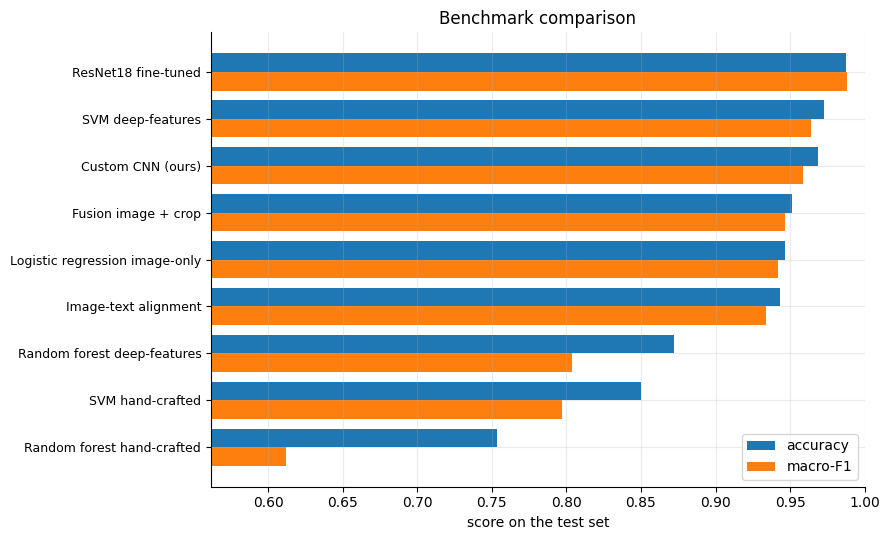

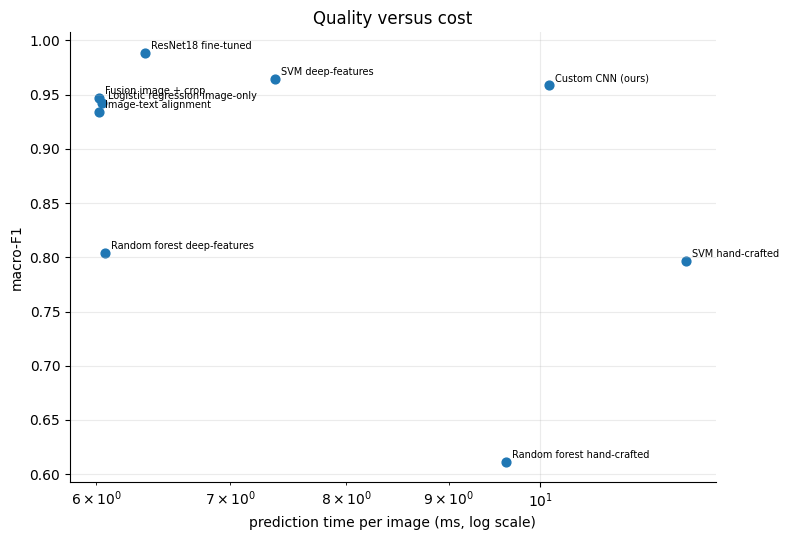

In [17]:
plot = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
yy = np.arange(len(plot))
ax.barh(yy + 0.2, plot["accuracy"], 0.4, label="accuracy", color="tab:blue")
ax.barh(yy - 0.2, plot["macro_f1"], 0.4, label="macro-F1", color="tab:orange")
ax.set_yticks(yy); ax.set_yticklabels(plot["model"], fontsize=9)
lo = min(plot["macro_f1"].min(), plot["accuracy"].min())
ax.set_xlim(max(0, lo - 0.05), 1.0)
ax.set_xlabel("score on the test set"); ax.set_title("Benchmark comparison")
ax.legend(loc="lower right")
save_show("benchmark_comparison")

total_ms = res["feature_ms_per_image"] + res["classifier_ms_per_image"]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(total_ms, res["macro_f1"], s=40, color="tab:blue")
for x_, y_, n in zip(total_ms, res["macro_f1"], res["model"]):
    ax.annotate(n, (x_, y_), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("prediction time per image (ms, log scale)"); ax.set_ylabel("macro-F1")
ax.set_title("Quality versus cost")
save_show("quality_vs_cost")

**Per-class view.** The heat map shows the F1 score of every method on every class. Rows with low values are the diseases that are hard for a method; classes that are hard for *all* methods (similar-looking diseases, or classes with few images) are the limit of the data rather than of one method.

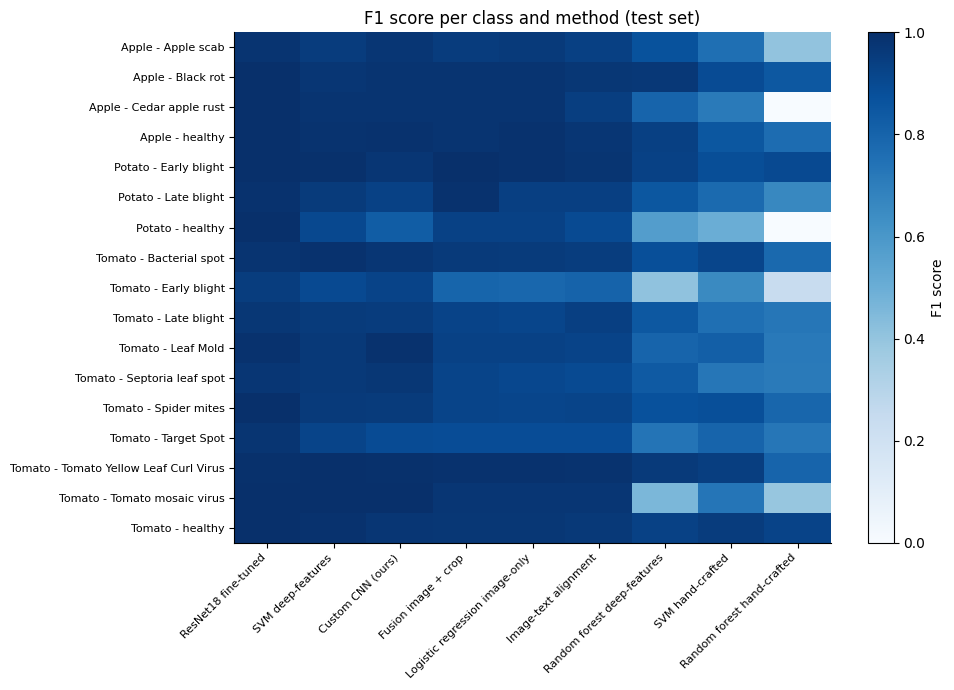

In [18]:
labels = list(range(K))
per_class = {n: precision_recall_fscore_support(y["test"], p, labels=labels, average=None, zero_division=0)[2]
             for n, p in test_preds.items()}
if cnn_pred_file.exists():
    cp = pd.read_csv(cnn_pred_file)
    rel = frames["test"]["path"].map(lambda p: str(Path(p).relative_to(ROOT_DIR)))
    merged = pd.DataFrame({"path": rel}).merge(cp, on="path", how="left")
    if merged["y_pred"].notna().all():
        per_class["Custom CNN (ours)"] = precision_recall_fscore_support(y["test"], merged["y_pred"].astype(int), labels=labels,
                                                                         average=None, zero_division=0)[2]
pc = pd.DataFrame(per_class, index=class_names)
pc = pc[[m for m in res["model"] if m in pc.columns]]

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(pc.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(pc.shape[1])); ax.set_xticklabels(pc.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(pc.shape[0])); ax.set_yticklabels(pc.index, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="F1 score")
ax.set_title("F1 score per class and method (test set)")
save_show("per_class_f1")
pc.round(3).to_csv(RESULTS / "per_class_f1.csv")

## Section 16 - Discussion

Write the discussion from the tables and charts above. The questions below guide it; each has a specific place to look.

1. **Classical vs deep.** Compare Benchmark 1 with 3 and 2 with 4 in the table. A large improvement from changing only the features means that learned features, not the classifier, explain the gap between classical and deep methods. Check the per-class heat map for the classes where hand-crafted features fail.
2. **SVM vs random forest.** Compare Benchmarks 1 with 2 and 3 with 4: does the margin-based classifier or the tree ensemble do better, and does the answer depend on the features? Note training time as well.
3. **What pretraining adds.** Compare the fine-tuned ResNet18 with the custom CNN trained from scratch (accuracy, macro-F1, training time, number of parameters, prediction time). Mohanty et al. (2016) found transfer learning always better; does that hold here?
4. **Does a second modality help?** Use the fusion table of Section 13: scores with and without crop metadata, and the number of cross-crop errors. State whether the improvement, if any, is large or small and why.
5. **Can text recognise unseen diseases?** Use the zero-shot results of Section 14: compare them with chance, say which classes are easier or harder and why (for example classes with unique symptoms, such as virus symptoms, against classes with similar descriptions).
6. **Quality versus cost.** Use the quality-versus-cost chart: which method gives the best result for its cost, and which would suit deployment on a phone?
7. **Which differences are real?** Differences of a few tenths of a percent can be noise. The results notebook runs a statistical test (McNemar's test on the saved predictions) to decide.

**Limitations.** (a) The classical models use a $128\times128$ HOG and PCA to keep them fast, so they may be slightly below their best possible performance. (b) Hyper-parameter tuning was deliberately small ($C\in\{1,10\}$ for the SVM, fixed forests) and ResNet18 was fine-tuned for only 5 epochs. (c) Single split and single seed. (d) The text encoder is simple TF-IDF, and the descriptions apply to whole classes, so the image-text results demonstrate the idea rather than the best achievable zero-shot performance; a pretrained text encoder or CLIP would be the natural next step. (e) PlantVillage's uniform backgrounds mean none of these scores predicts field performance.

## Section 17 - Saved Outputs

Everything produced here is stored for the results notebook: predictions of all benchmarks in `results/predictions/` (columns `path`, `y_true`, `y_pred`), the comparison tables, per-class scores and zero-shot results in `results/benchmarks/`, the fine-tuned network in `models/`, and cached features in `data/features/`.

In [19]:
for folder in (PRED_DIR, RESULTS):
    print(folder.relative_to(ROOT_DIR))
    for f in sorted(folder.glob("*")):
        print("   ", f.name)

results/predictions
    custom_cnn_metrics.json
    custom_cnn_test_predictions.csv
    fusion_image_crop_test_predictions.csv
    image_text_alignment_test_predictions.csv
    logistic_regression_image_only_test_predictions.csv
    random_forest_deep_features_test_predictions.csv
    random_forest_hand_crafted_test_predictions.csv
    resnet18_fine_tuned_test_predictions.csv
    svm_deep_features_test_predictions.csv
    svm_hand_crafted_test_predictions.csv
results/benchmarks
    benchmark_comparison.csv
    benchmark_comparison.png
    fusion_errors.png
    per_class_f1.csv
    per_class_f1.png
    quality_vs_cost.png
    zero_shot.png
    zero_shot_results.csv


## References

Baltrusaitis, T., Ahuja, C. & Morency, L.-P. 2019, Multimodal machine learning: a survey and taxonomy, *IEEE Transactions on Pattern Analysis and Machine Intelligence*, vol. 41, no. 2, pp. 423-443.

Benabbas, W., Brahimi, M., Akhrouf, S. & Fortas, B. 2025, Rethinking plant disease diagnosis: bridging the academic-practical gap with vision transformers and zero-shot learning, arXiv:2511.18989.

Breiman, L. 2001, Random forests, *Machine Learning*, vol. 45, no. 1, pp. 5-32.

Cortes, C. & Vapnik, V. 1995, Support-vector networks, *Machine Learning*, vol. 20, pp. 273-297.

Dalal, N. & Triggs, B. 2005, Histograms of oriented gradients for human detection, *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*.

Frome, A., Corrado, G. S., Shlens, J. et al. 2013, DeViSE: a deep visual-semantic embedding model, *Advances in Neural Information Processing Systems*, vol. 26.

He, K., Zhang, X., Ren, S. & Sun, J. 2016, Deep residual learning for image recognition, *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, pp. 770-778.

Lampert, C. H., Nickisch, H. & Harmeling, S. 2014, Attribute-based classification for zero-shot visual object categorization, *IEEE Transactions on Pattern Analysis and Machine Intelligence*, vol. 36, no. 3, pp. 453-465.

Mohanty, S. P., Hughes, D. P. & Salathe, M. 2016, Using deep learning for image-based plant disease detection, *Frontiers in Plant Science*, vol. 7, article 1419, <https://doi.org/10.3389/fpls.2016.01419>.

Mokhtar, U., Ali, M. A., Hassanien, A. E. & Hefny, H. 2015, Identifying two of tomatoes leaf viruses using support vector machine, in *Information Systems Design and Intelligent Applications*, Springer, pp. 771-782.

Radford, A., Kim, J. W., Hallacy, C. et al. 2021, Learning transferable visual models from natural language supervision, *Proceedings of the 38th International Conference on Machine Learning*, PMLR 139, pp. 8748-8763.

Yosinski, J., Clune, J., Bengio, Y. & Lipson, H. 2014, How transferable are features in deep neural networks?, *Advances in Neural Information Processing Systems*, vol. 27.